(dose-response-guide)=
# Dose response per cell type

Find which genes respond to a dose in each cell type of a dose series, how, the shape of each response, which responses turn, from which dose, and the dose at which each response reaches a stated change, its benchmark dose, with {api}`dose_response`, and check the calls against noise with {api}`permutation_check`. The series here is simulated from known curves by {api}`simulate_dose_series`, so its truth says which genes respond: 27 mice, 3 for the vehicle and for each of eight doses from 0.01 to 30 ug/kg in half-log steps, with hepatocytes, macrophages, stellate cells and cholangiocytes, of which 20%, 15%, 5% and 10% of 2,000 genes respond. Hepatocytes and stellate cells fall by half and macrophages double at the top dose, and cholangiocytes are rare. [Dose response](../statistics/dose_response.md) explains the methods.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import (
    BenchmarkResponse,
    CandidateShapes,
    Design,
    DoseAxis,
    DoseTruth,
    dose_response,
    gsva,
    permutation_check,
    read_cube,
)
from cytepool.plotting import plot_dose_response

# The cube, and the truth of each cell type.
cube = read_cube("simulated_dose_series.cube.zarr")
truth = DoseTruth(**json.loads(Path("simulated_dose_series_truth.json").read_text()))
print(f"CytePool {cytepool.__version__}")
print(cube)

CytePool 0.1.1.dev23+gcde13c0ac.d20261123
Cube with 27 samples x 4 groups x 2,000 features
  layers: counts (uint32, lazy)
  filled: 108 of 108 sample x group entries have cells (100.0%)
  samples: sample_id, dose, dose_group, donor
  groups: group_id
  features: feature_id


Each sample is one mouse's pseudobulk profile in one cell type: the sum of its cells' counts. The sample table holds each mouse's `dose`, 0 for the vehicle.

## Place the doses on an axis

Where does each dose sit on the curve's axis? The doses are spaced by half a log10, so the curves follow log10 dose, and the vehicle, whose dose of 0 has no logarithm, forms a group of its own, the default of {api}`DoseAxis`:

In [2]:
axis = DoseAxis("dose", unit=truth.unit, metric=truth.metric)
print(axis)

DoseAxis(column='dose', unit='ug/kg', metric='administered', scale='log10', vehicle='own_group', offset=None)


## Test every cell type

Which genes respond in each cell type? {api}`dose_response` takes the design of the terms other than dose, here none (`"~ 1"`). It checks the design first, as {api}`check_dose_design` does, so that check needs no call of its own, and tests the cell types that support tests:

In [3]:
result = dose_response(cube, Design(cube.samples, "~ 1"), dose=axis)
print(result)

DoseResponseResult (limma_voom): 4 cell types, 3 tested; tests: spline,
    nonlinearity, linear_trend, dose_groups
  dose: ug/kg (administered) on a log10 axis, the vehicle in a group of its own;
        spline of 2 columns, knots at 0.548 ug/kg, boundary knots at 0.01 and 30
        ug/kg; linear_trend slopes per log10 unit of dose
  gate: spline test, Benjamini-Hochberg within each cell type, at 5% FDR
  Hepatocyte: 9 dose groups, 27 samples, 1,869 genes; 230 pass the gate; calls
              at 5% FDR: spline 230, nonlinearity 98, linear_trend 205,
              dose_groups 201
  Macrophage: 9 dose groups, 27 samples, 1,484 genes; 113 pass the gate; calls
              at 5% FDR: spline 113, nonlinearity 41, linear_trend 94,
              dose_groups 104
  Stellate: 9 dose groups, 27 samples, 845 genes; 17 pass the gate; calls at 5%
            FDR: spline 17, nonlinearity 3, linear_trend 12, dose_groups 10
  Cholangiocyte: not tested, descriptive: no treated dose group that can b

The printout gives the spline's knot in doses, the gate, which decides which genes count as responding, and, for each cell type, the dose groups it compares, its samples and genes, the genes that pass the gate and the genes each test calls at 5% FDR. Read `spline` first, the default gate: it asks whether a gene responds at all. `linear_trend` and `nonlinearity` describe the responses it finds, and `dose_groups` asks the same question as `spline` without a curve. The cholangiocytes are not tested: few of their profiles keep 10 cells, so no dose has a second replicate, and the check calls them descriptive. Its report stays in the result:

In [4]:
report = result.design_report
report.doses.filter(group_id="Cholangiocyte").select(
    ["dose", "n_samples_used", "n_cells_min"]
)

Table with 9 rows and 3 columns
  dose     n_samples_used  n_cells_min
  float64  int64           float64
  0.0      1               17.0
  0.01     0               nan
  0.03     1               13.0
  0.1      0               nan
  0.3      1               10.0
  1.0      1               11.0
  3.0      0               nan
  10.0     1               14.0
  30.0     1               13.0

## Read a test's table

What does each gene's row say? The table of a test has one row per gene that passes the expression filter, here the first five rows of the hepatocytes' spline, sorted by p-value:

In [5]:
# The table of the hepatocytes' spline test, and its five genes of smallest p-value.
spline = result.table("Hepatocyte", "spline")
top = spline.sort("p_value").take(range(5))
print(
    f"{'feature_id':<12}{'f_statistic':>12}{'p_value':>10}{'adjusted_p_value':>18}"
    f"{'adjusted_p_value_across_groups':>32}"
)
for gene, f_statistic, p_value, adjusted, across in zip(
    top["feature_id"],
    top["f_statistic"],
    top["p_value"],
    top["adjusted_p_value"],
    top["adjusted_p_value_across_groups"],
):
    print(
        f"{gene:<12}{f_statistic:>12.1f}{p_value:>10.2g}{adjusted:>18.2g}{across:>32.2g}"
    )

feature_id   f_statistic   p_value  adjusted_p_value  adjusted_p_value_across_groups
gene_0295          163.6   4.5e-19           3.2e-16                         3.6e-16
gene_0896          163.6   4.5e-19           3.2e-16                         3.6e-16
gene_0046          162.1   5.1e-19           3.2e-16                         3.6e-16
gene_0342          111.4   1.1e-16           5.2e-14                         5.2e-14
gene_0708           98.4   6.4e-16           2.4e-13                         2.7e-13


`f_statistic` and `p_value` test the gene; `adjusted_p_value` adjusts the p-values of the cell type by Benjamini-Hochberg, and `adjusted_p_value_across_groups` those of every cell type at once. The table of the linear trend, `result.table("Hepatocyte", "linear_trend")`, has a `log2_fold_change`, the slope of a straight line along the axis, the change per log10 unit of dose, and `result.table("Hepatocyte", "each_dose")` tests each dose against the vehicle.

## Compare the calls with the truth

How many of the genes that respond does each test find, and how many flat genes does it call? The truth knows each gene's maximal change:

In [6]:
for cell_type in ("Hepatocyte", "Macrophage", "Stellate"):
    genes = truth.table(cell_type)
    change = dict(
        zip(genes["feature_id"].tolist(), np.abs(genes["max_log2_change"]).tolist())
    )
    for test in result.tests:
        table = result.table(cell_type, test)
        called = np.asarray(table["adjusted_p_value"]) <= 0.05
        responds = np.array([change[g] > 0 for g in table["feature_id"].tolist()])
        print(
            f"{cell_type:<11} {test:<13} {called[responds].sum():>3} of "
            f"{responds.sum()} responsive genes, {called[~responds].sum()} of "
            f"{(~responds).sum()} flat"
        )

Hepatocyte  spline        222 of 378 responsive genes, 8 of 1491 flat
Hepatocyte  nonlinearity   93 of 378 responsive genes, 5 of 1491 flat
Hepatocyte  linear_trend  194 of 378 responsive genes, 11 of 1491 flat
Hepatocyte  dose_groups   194 of 378 responsive genes, 7 of 1491 flat
Macrophage  spline        109 of 223 responsive genes, 4 of 1261 flat
Macrophage  nonlinearity   40 of 223 responsive genes, 1 of 1261 flat
Macrophage  linear_trend   90 of 223 responsive genes, 4 of 1261 flat
Macrophage  dose_groups   100 of 223 responsive genes, 4 of 1261 flat
Stellate    spline         17 of 49 responsive genes, 0 of 796 flat
Stellate    nonlinearity    3 of 49 responsive genes, 0 of 796 flat
Stellate    linear_trend   12 of 49 responsive genes, 0 of 796 flat
Stellate    dose_groups    10 of 49 responsive genes, 0 of 796 flat


With three mice per dose, the spline finds about 6 in 10 of the hepatocytes' responses and calls 8 of their 1,491 flat genes. The stellate cells, with 40 cells per profile, give noisier profiles, and their spline finds about a third of their responses. The non-linearity test calls fewer genes: only the responses that bend away from a straight line along log10 dose, such as bells and steps.

## See the shape of a response

What shape does a response take? {api}`plot_dose_response` draws each dose's estimate against the vehicle, the fitted spline and its 95% band; the true curves are drawn dashed over them:

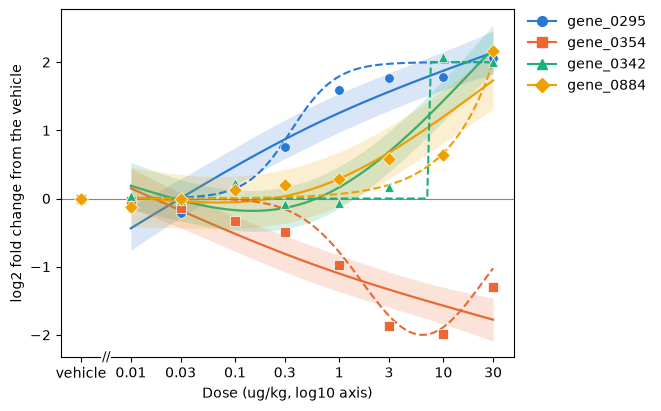

gene_0295: hill, gene_0354: log_gauss_probit, gene_0342: step, gene_0884: linear


In [7]:
called = spline.filter(spline["adjusted_p_value"] <= 0.05)
truths = truth.table("Hepatocyte")
shape_of = dict(zip(truths["feature_id"].tolist(), truths["shape"].tolist()))
# The gene of smallest p-value of each of four shapes.
ordered = called.sort("p_value")["feature_id"].tolist()
shapes = ("hill", "log_gauss_probit", "step", "linear")
picked = [next(g for g in ordered if shape_of[g] == shape) for shape in shapes]
ax = plot_dose_response(result, "Hepatocyte", genes=picked)
# The true curves, dashed, in the colours of the fitted ones.
grid = np.geomspace(0.01, 30.0, 100)
true = truth.curve("Hepatocyte", picked, at=grid)
fitted = [line for line in ax.get_lines() if line.get_gid() == "curve"]
for line, values in zip(fitted, true, strict=True):
    ax.plot(axis.positions(grid), values, linestyle="--", color=line.get_color())
plt.show()
print(", ".join(f"{g}: {shape_of[g]}" for g in picked))

A spline of two columns follows its gene's dose groups only as far as its shape allows. The Hill gene (gene_0295) rises more steeply between 0.3 and 3 ug/kg than its spline, which also starts at -0.4 at 0.01 ug/kg, where the true change is 0; its band misses the true curve at 4 of the 8 doses. The bell (gene_0354) turns back above 10 ug/kg while its spline keeps falling, and its band misses the true curve from 0.1 ug/kg up. The step's spline (gene_0342) smooths its jump at 7 ug/kg, and the straight line in dose (gene_0884), which climbs only at the top doses, gets a spline that rises earlier; both bands miss at 3 and 10 ug/kg. A band holds the spline that the true means of the dose groups would give, not every true curve, so read it beside the dose points, which lie closer to the truth. With the vehicle in a group of its own, each curve starts at the lowest dose, a jump from the vehicle's 0 left of the axis break. A larger `spline_df` follows such shapes more closely at some cost in power, and the non-linearity test flags the responses that bend.

## Fit named curves

What shape does each response take, in the curves that toxicologists report? With `models`, {api}`dose_response` also fits named curves to every gene: `"epa"` holds the eight models of EPA's Transcriptomic Assessment Products in the forms of BMDS, from a straight line to the Hill curve and four exponential curves. Each gene gets every model's parameters and fit, and its best model by AICc, Akaike's criterion corrected for small samples. For the four genes of the figure above:

In [8]:
fitted = dose_response(cube, Design(cube.samples, "~ 1"), dose=axis, models="epa")
curves = fitted.table("Hepatocyte", "curves")
best = curves.filter(curves["best"])
row_of = {gene: row for row, gene in enumerate(best["feature_id"].tolist())}
for gene in picked:
    row = row_of[gene]
    print(
        f"{gene} ({shape_of[gene]}): {best['model'][row]}, Akaike weight "
        f"{best['akaike_weight'][row]:.2f}, lack-of-fit p = "
        f"{best['lack_of_fit_p_value'][row]:.2g}"
    )
# The Hill gene's Hill curve: its parameters beside the true EC50.
hill = curves.filter((curves["feature_id"] == picked[0]) & (curves["model"] == "hill"))
ec50 = truths.filter(truths["feature_id"] == picked[0])["ec50"][0]
values = ", ".join(f"{name} {hill[name][0]:.2f}" for name in ("g", "v", "k", "n"))
print(f"{picked[0]}'s Hill curve: {values}; true EC50 {ec50:.2f} {axis.unit}")

gene_0295 (hill): hill, Akaike weight 0.57, lack-of-fit p = 0.13
gene_0354 (log_gauss_probit): exponential_4, Akaike weight 0.79, lack-of-fit p = 0.00021
gene_0342 (step): exponential_5, Akaike weight 0.50, lack-of-fit p = 0.49
gene_0884 (linear): linear, Akaike weight 0.33, lack-of-fit p = 0.42
gene_0295's Hill curve: g 8.27, v 2.02, k 0.35, n 1.60; true EC50 0.35 ug/kg


The Hill gene's best model is the Hill curve, with 57% of the gene's support among the eight models (`akaike_weight`), and its lack-of-fit p-value of 0.13, above 0.1, says that the curve passes through the dose groups' means within their noise. Its parameters read as a pharmacologist reads them: g is the vehicle's level, v the full change, k the dose of half the change, the EC50, and n the steepness; k is 0.35 ug/kg, as the true EC50 is. The bell's best model is exponential 4, a fall to a plateau that cannot turn back, which its lack-of-fit p-value of 0.00021 flags. The step's best model is exponential 5, tied with the Hill curve at half the support each: both rise steeply with their exponent at its bound of 18. The straight line in dose gets the line, with a third of the support: models of more parameters fit it almost as well. Over the 230 genes that the spline calls in the hepatocytes, the best models against the true shapes:

In [9]:
calls = set(called["feature_id"].tolist())
pairs = Counter(
    (shape_of[gene], model)
    for gene, model in zip(best["feature_id"].tolist(), best["model"].tolist())
    if gene in calls
)
for shape in sorted({shape for shape, _ in pairs}):
    found = ", ".join(f"{m} {n}" for (s, m), n in pairs.most_common() if s == shape)
    print(f"{shape:17} {found}")

exponential       exponential_4 14, hill 13, exponential_2 1, linear 1
flat              linear 3, exponential_2 2, exponential_4 2, hill 1
frechet           hill 11, exponential_4 8, exponential_5 4, exponential_3 1, exponential_2 1
hill              exponential_4 26, hill 18, linear 7, exponential_2 3, exponential_5 1, exponential_3 1
linear            exponential_2 9, linear 2
log_gauss_probit  exponential_4 21, hill 13, linear 10, exponential_2 6, exponential_5 6
power             linear 5, exponential_3 4, exponential_2 4, power 2, hill 1, polynomial_2 1
step              exponential_5 10, hill 10, exponential_4 4, exponential_2 2, power 2


With three mice per dose, a shape is seldom told apart from its neighbours. Hill responses go to exponential 4 more often than to the Hill curve, which differ mostly in how they approach their plateau, and Fréchet curves, steps and bells, which no EPA model contains, go to the nearest monotone curves. The Akaike weights show how close each call is, and the lack-of-fit p-values which curves miss the means. {api}`plot_dose_response` with `model` draws each gene's curve of a model, here its best, through the dose groups' means that the curves were fitted to, with the true curves dashed:

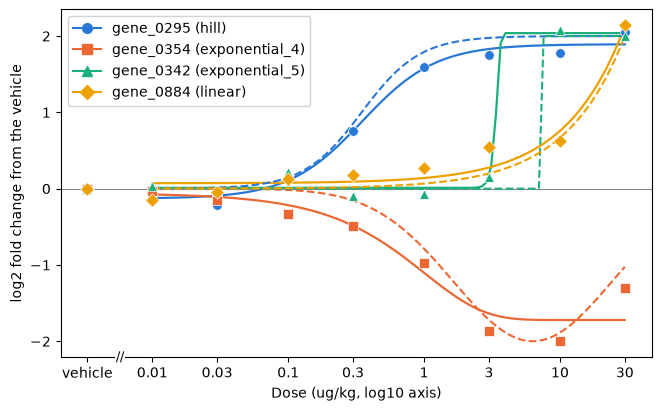

In [10]:
ax = plot_dose_response(fitted, "Hepatocyte", genes=picked, model="best")
drawn = [line for line in ax.get_lines() if line.get_gid() == "model_curve"]
for line, values in zip(drawn, true, strict=True):
    ax.plot(axis.positions(grid), values, linestyle="--", color=line.get_color())
plt.show()

The Hill gene's curve follows its true curve, and the line's rises at the top doses as the truth does. The bell's exponential 4 curve falls to a plateau near -1.7 and stays there, where the true curve turns back above 10 ug/kg. The step's exponential 5 curve rises between 3.1 and 3.7 ug/kg, while the true step is at about 7 ug/kg: with doses of 3 and 10 ug/kg, the data place a step only somewhere between them. The cholangiocytes, which support only description, get curves too, under constant variance and without lack-of-fit p-values:

In [11]:
cholangiocytes = fitted.curve_fits("Cholangiocyte")
print(cholangiocytes)
missing = np.isnan(cholangiocytes.lack_of_fit_p_value).all()
print("lack-of-fit p-values:", "none" if missing else "some")

DoseCurveFits (epa, constant variance): 307 genes, 6 dose groups; models:
    linear, polynomial_2, power, hill, exponential_2, exponential_3,
    exponential_4, exponential_5
  best: exponential_2 154, linear 153
lack-of-fit p-values: none


With one mouse in each of the 6 dose groups, the vehicle's included, 6 samples in all, AICc's correction for small samples is infinite for a model of 4 parameters and puts one of 3 parameters 30 above the line: the best model of each of the 307 genes is a line or exponential 2.

## Find responses that turn

Which responses rise and then fall? `"dromics"` adds DRomics' Gauss-probit curves, the only models whose slope can change sign within the doses. A bell can also fit one outlying dose group, so each gene whose best fit turns is fitted again without each dose group in turn, and `turn_driven_by_dose` gives the lowest dose without whose group the best fit no longer turns, 0 for the vehicle's group; `numpy.isfinite` tells the turns that one group drives:

In [12]:
turning = dose_response(
    cube, Design(cube.samples, "~ 1"), dose=axis, models="dromics", groups="Hepatocyte"
)
best = turning.table("Hepatocyte", "curves")
best = best.filter(best["best"])
turns = np.isfinite(best["turn_dose"])
driven = np.isfinite(best["turn_driven_by_dose"])
shape = np.array([shape_of[gene] for gene in best["feature_id"].tolist()])
spline_calls = np.isin(best["feature_id"], list(calls))
for genes, among in (("all genes", True), ("the spline's calls", spline_calls)):
    print(f"{genes}:")
    for label, chosen in (
        ("true bells", shape == "log_gauss_probit"),
        ("monotone responses", (shape != "log_gauss_probit") & (shape != "flat")),
        ("flat genes", shape == "flat"),
    ):
        chosen = chosen & among
        print(
            f"  {label:18} {chosen.sum():5,} genes: best fit turns in "
            f"{np.sum(turns & chosen):4,}, driven by one dose group in "
            f"{np.sum(turns & chosen & driven):4,}, without in "
            f"{np.sum(turns & chosen & ~driven):3,}"
        )

all genes:
  true bells            77 genes: best fit turns in   60, driven by one dose group in   28, without in  32
  monotone responses   301 genes: best fit turns in   60, driven by one dose group in   57, without in   3
  flat genes         1,491 genes: best fit turns in  293, driven by one dose group in  278, without in  15
the spline's calls:
  true bells            56 genes: best fit turns in   49, driven by one dose group in   19, without in  30
  monotone responses   166 genes: best fit turns in   41, driven by one dose group in   39, without in   2
  flat genes             8 genes: best fit turns in    4, driven by one dose group in    3, without in   1


Turning best fits are common: 293 of the 1,491 flat genes get one, and so do 60 of the 301 monotone responses, but one dose group drives nearly all of these turns, 278 and 57. Of the 77 true bells, 60 have a turning best fit and 32 keep their turn without each group, yet so do 15 flat genes and 3 monotone responses: only 32 of the 50 turns that keep are bells. Among the 230 genes that the spline calls, 30 of the 33 turns that keep are bells. So read turns among the genes that a test calls, and keep those that turn without each group.

## Test a few expected shapes

Does a response follow one of a few expected shapes, or grow with dose? The spline finds responses of any shape. Two multiple contrast tests ask the narrower questions: the MCP step of MCP-Mod (multiple comparison procedure and modelling) tests a few candidate shapes, and the Williams-type test responses that grow in dose order. On 20,000 genes and 7 doses they add 10 to 23 s each to the 0.9 s of the default tests, so they run only when named in `tests`, here beside the spline. {api}`CandidateShapes.spread` places the default shapes over the doses, as `dose_response` does when no `candidates` are given; each shape's change is 1 at the top dose, or at its peak:

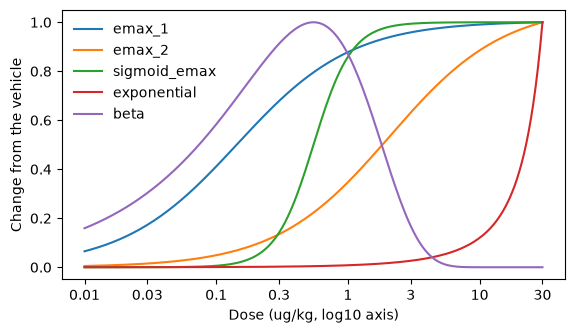

In [13]:
shapes = CandidateShapes.spread(axis, cube.samples)
# Each shape along the axis's log10 positions, with a tick at each treated dose.
grid = np.geomspace(0.01, 30.0, 200)
doses = np.unique(np.asarray(cube.samples["dose"]))[1:]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for name, values in zip(shapes.names, shapes.means(grid), strict=True):
    ax.plot(axis.positions(grid), values, label=name)
ax.set_xticks(axis.positions(doses), [f"{d:g}" for d in doses])
ax.set(xlabel="Dose (ug/kg, log10 axis)", ylabel="Change from the vehicle")
ax.legend(frameon=False)
plt.show()

Two Emax shapes rise early and midway along log dose, the sigmoid Emax shape rises steeply midway, the exponential shape rises late, at the top doses, and the beta shape rises to a peak midway and falls back by 10 ug/kg. The two multiple contrast tests run beside the spline:

In [14]:
shaped = dose_response(
    cube,
    Design(cube.samples, "~ 1"),
    dose=axis,
    tests=("spline", "williams", "mcp"),
    rng=1,
)
print(shaped)

DoseResponseResult (limma_voom): 4 cell types, 3 tested; tests: spline,
    williams, mcp
  dose: ug/kg (administered) on a log10 axis, the vehicle in a group of its own;
        spline of 2 columns, knots at 0.548 ug/kg, boundary knots at 0.01 and 30
        ug/kg
  gate: spline test, Benjamini-Hochberg within each cell type, at 5% FDR
  Hepatocyte: 9 dose groups, 27 samples, 1,869 genes; 230 pass the gate; calls
              at 5% FDR: spline 230, williams 172, mcp 235
  Macrophage: 9 dose groups, 27 samples, 1,484 genes; 113 pass the gate; calls
              at 5% FDR: spline 113, williams 92, mcp 121
  Stellate: 9 dose groups, 27 samples, 845 genes; 17 pass the gate; calls at 5%
            FDR: spline 17, williams 11, mcp 18
  Cholangiocyte: not tested, descriptive: no treated dose group that can be
                 compared with the vehicle keeps a second sample, so no dose has
                 a replicate


`rng` seeds the Monte Carlo error of the p-values, so they reproduce. Which responses does each test find, and how many flat genes does it call? Count the calls at 5% FDR by true shape:

In [15]:
genes = truth.table("Hepatocyte")
shape_of = dict(zip(genes["feature_id"].tolist(), genes["shape"].tolist()))
order = [
    "hill",
    "exponential",
    "linear",
    "power",
    "log_gauss_probit",
    "frechet",
    "step",
    "flat",
]
tested = shaped.table("Hepatocyte", "spline")["feature_id"].tolist()
called = {}
for test in ("spline", "williams", "mcp"):
    table = shaped.table("Hepatocyte", test)
    called[test] = set(
        table.filter(table["adjusted_p_value"] <= 0.05)["feature_id"].tolist()
    )
print(f"{'shape':<18}{'genes':>6}{'spline':>8}{'williams':>10}{'mcp':>6}")
for shape in order:
    members = [g for g in tested if shape_of[g] == shape]
    found = [sum(g in called[test] for g in members) for test in called]
    print(f"{shape:<18}{len(members):>6}{found[0]:>8}{found[1]:>10}{found[2]:>6}")

shape              genes  spline  williams   mcp
hill                 112      56        46    55
exponential           55      29        22    27
linear                20      11         9    13
power                 36      17        15    22
log_gauss_probit      77      56        35    54
frechet               39      25        17    25
step                  39      28        21    27
flat                1491       8         7    12


The MCP step finds 223 of the 378 responses and the spline 222, and they call 12 and 8 of the 1,491 flat genes; the Williams-type test finds 165 and calls 7. The MCP step and the spline both find most of the 77 bells, the `log_gauss_probit` curves that rise and fall back, 54 and 56, where the Williams-type test finds 35: it pools the top doses, where a bell has fallen back. Which candidate shape does the MCP step name for the genes it calls?

In [16]:
# The candidate shape of each called gene's largest |t|, by the gene's true shape.
mcp = shaped.table("Hepatocyte", "mcp")
calls = mcp.filter(mcp["adjusted_p_value"] <= 0.05)
for true_shape in ("exponential", "power", "log_gauss_probit"):
    contrasts = Counter(
        contrast
        for gene, contrast in zip(
            calls["feature_id"].tolist(), calls["contrast"].tolist()
        )
        if shape_of[gene] == true_shape
    )
    print(
        f"{true_shape:<17} " + ", ".join(f"{n} {k}" for n, k in contrasts.most_common())
    )

exponential       emax_1 16, emax_2 10, exponential 1
power             exponential 21, emax_2 1
log_gauss_probit  beta 17, sigmoid_emax 14, emax_2 14, emax_1 7, exponential 2


Of the 27 exponential curves the MCP step calls, 26 have an Emax shape as their strongest contrast, and 21 of the 22 power curves the candidate exponential shape: the simulator's exponential curves, BMDS's exponential 4, level off as the Emax shapes do, while the candidate exponential shape, BMDS's exponential 2, rises late, as power curves do. The beta shape is the strongest contrast for 17 of the 54 bells, and Emax or sigmoid Emax shapes for most of the others, since many bells turn back only at the top doses, where they look monotone. So `contrast` names the candidate whose contrast best matches a gene's observed changes, not the gene's shape: the shapes' contrasts are strongly correlated, and fitting and choosing a shape is MCP-Mod's modelling step, not implemented yet.

## Choose which genes count as responding

Which genes count as responding to the dose? Each test calls its own genes, and one decides: the gate, the spline test at 5% FDR by default, as the printout's `gate` line says. Its table gives each gene's call in `passes_gate`:

In [17]:
gate = result.table("Hepatocyte", "gate")
print(result.gate)
print(
    f"{int(np.sum(gate['passes_gate']))} of {len(gate):,} hepatocyte genes pass the gate"
)

{'test': 'spline', 'fdr': 0.05, 'fold_change': None}
230 of 1,869 hepatocyte genes pass the gate


A gate can also ask for a change beyond a size: with `gate={"fold_change": 1.5}`, each dose's change is tested against 1.5-fold by TREAT, so that the threshold is part of each test, and a gene passes when one of its doses changes by more.

In [18]:
large = dose_response(
    cube, Design(cube.samples, "~ 1"), dose=axis, gate={"fold_change": 1.5}
)
print(large.gate)
passing = np.asarray(large.table("Hepatocyte", "gate")["passes_gate"])
print(f"{passing.sum()} of {passing.size:,} hepatocyte genes pass the 1.5-fold gate")

{'test': 'each_dose', 'fdr': 0.05, 'fold_change': 1.5}
75 of 1,869 hepatocyte genes pass the 1.5-fold gate


How do its genes compare with the truth, beside the default gate and the default gate followed by a cut at 1.5-fold on the estimated changes?

In [19]:
# Each gene's largest true change over the treated doses, and its estimated changes.
treated = np.unique(np.asarray(cube.samples["dose"]))[1:]
true = np.abs(truth.curve("Hepatocyte", gate["feature_id"].tolist(), at=treated))
beyond, flat = true.max(axis=1) > np.log2(1.5), true.max(axis=1) == 0
each = result.table("Hepatocyte", "each_dose")
estimated = np.abs(np.asarray(each["log2_fold_change"])).reshape(treated.size, -1).T
passes = np.asarray(gate["passes_gate"])
cut = passes & (estimated >= np.log2(1.5)).any(axis=1)
calls = {
    "default gate": passes,
    "default gate, then a 1.5-fold cut": cut,
    "1.5-fold gate": passing,
}
print(f"{beyond.sum()} of the {passes.size:,} genes change beyond 1.5-fold in truth")
for name, found in calls.items():
    print(
        f"{name:<34}{found.sum():>4} genes: {np.sum(found & beyond):>3} beyond "
        f"1.5-fold, {np.sum(found & ~beyond & ~flat):>2} below, "
        f"{np.sum(found & flat):>2} flat"
    )

215 of the 1,869 genes change beyond 1.5-fold in truth
default gate                       230 genes: 181 beyond 1.5-fold, 41 below,  8 flat
default gate, then a 1.5-fold cut  216 genes: 178 beyond 1.5-fold, 33 below,  5 flat
1.5-fold gate                       75 genes:  75 beyond 1.5-fold,  0 below,  0 flat


Of the 215 genes whose true change exceeds 1.5-fold at some dose, the 1.5-fold gate passes 75 and no other gene. The cut after the default gate keeps 216 genes, 38 of them never beyond 1.5-fold in truth and 5 of those flat: an estimated change exceeds the threshold by chance as often as the noise allows, so a cut controls no error rate for the size of a change. TREAT asks for evidence that the change exceeds the threshold, so it passes the changes that lie well beyond it and leaves out many genes near it.

## Check the calls against noise

Could the genes that pass the gate come from noise at this design? {api}`permutation_check` permutes the doses among the mice, runs the analysis of each cell type again on each permuted labelling, and counts the genes that the gate passes, here in 100 runs per cell type; its p-value tests whether the true doses pass more genes than permuted ones:

In [20]:
check = permutation_check(result, n_permutations=100, rng=1)
print(check)

PermutationCheck of the gate (spline test, Benjamini-Hochberg within each cell
    type, at 5% FDR): 4 cell types, 3 checked; seed 1
  Hepatocyte: 230 genes pass the gate; over 100 random runs of 1.1e21
              assignments, the gate passed genes in 9 runs (0.09), 0.51 genes
              per run; p = 0.0099, the smallest these runs can give
  Macrophage: 113 genes pass the gate; over 100 random runs of 1.1e21
              assignments, the gate passed genes in 11 runs (0.11), 0.41 genes
              per run; p = 0.0099, the smallest these runs can give
  Stellate: 17 genes pass the gate; over 100 random runs of 1.1e21 assignments,
            the gate passed genes in 14 runs (0.14), 0.14 genes per run; p =
            0.0099, the smallest these runs can give
  Cholangiocyte: not checked: cell type 'Cholangiocyte' was not tested
                 (descriptive): no treated dose group that can be compared with
                 the vehicle keeps a second sample, so no dose has a repl

In every cell type, no run passed as many genes as the true doses, so each p-value is 1/101, the smallest that 100 runs can give; even the stellate cells, with 17 genes, pass more with their doses than in any run. The runs passed genes in 9 to 14 of 100, a few genes at a time. Which genes pass in those runs? Each run's doses are in the provenance, so a run can be made again with {api}`dose_response` and the result's seed, here the hepatocytes' first run that passed genes:

In [21]:
entry = next(e for e in check.provenance["groups"] if e["group_id"] == "Hepatocyte")
runs = np.asarray(check.table("Hepatocyte")["n_genes_passing_gate"])
sample_ids = cube.samples["sample_id"].tolist()


def remade(run):
    """dose_response on the hepatocytes with the doses that a run recorded."""
    doses = np.array(cube.samples["dose"], dtype=float)
    for sample, label in zip(entry["samples"], entry["assignments"][run]):
        doses[sample_ids.index(sample)] = entry["doses"][label]
    permuted = Design(cube.samples.with_columns({"dose": doses}), "~ 1")
    return dose_response(cube, permuted, dose=axis, groups="Hepatocyte")


first = int(np.flatnonzero(runs)[0])
again = remade(first).table("Hepatocyte", "gate")
print(
    f"run {first + 1}: {again['passes_gate'].sum()} genes pass; the check counted {runs[first]}"
)

run 9: 17 genes pass; the check counted 17


Made again, the run passes the genes the check counted. Which genes pass in the runs? Each of the hepatocytes' runs that passed genes, against the truth:

In [22]:
truths = truth.table("Hepatocyte")
size = dict(
    zip(truths["feature_id"].tolist(), np.abs(truths["max_log2_change"]).tolist())
)
passed = []
for run in np.flatnonzero(runs):
    table = remade(run).table("Hepatocyte", "gate")
    passed += table.filter(table["passes_gate"])["feature_id"].tolist()
responsive = sum(size[gene] > 0 for gene in passed)
print(
    f"{len(passed)} genes passed in {np.count_nonzero(runs)} runs; "
    f"{responsive} of them respond in truth"
)

51 genes passed in 9 runs; 47 of them respond in truth


Most genes that pass in the runs respond in truth: the runs keep every gene's response, scrambled over the permuted dose groups, and a strong response still passes in a run that leaves most of a dose group's mice together. So the share of runs with genes says how often the gate passes genes with these mice's doses shuffled, not how often it passes noise, which only data without responses show, such as vehicle-only data placed in mock dose groups. The answer to this section's question is the p-value: in each cell type the true doses pass more genes than any of 100 permuted labellings, so not all of the gate's calls are noise, though the p-value does not say which calls are false ([Could the calls come from noise?](../statistics/dose_response.md#dose-permutation-check)).

## Find the lowest dose with an effect

From which dose does each gene respond? {api}`DoseResponseResult.lowest_effective_doses` calls each dose against the vehicle in the genes that pass the gate, at the level that keeps the overall false discovery rate of the genes at 5%, and gives the lowest dose called:

In [23]:
lowest = shaped.lowest_effective_doses("Hepatocyte")
called = lowest.filter(lowest["passes_gate"])
with_dose = called.filter(np.isfinite(np.asarray(called["lowest_effective_dose"])))
print(f"{len(called)} genes pass the gate; {len(with_dose)} have a dose called")
# The five genes of smallest stage-wise adjusted p-value, rounded.
top = called.sort("stage_wise_adjusted_p_value").take(range(5))
for gene, dose, change, p, n in zip(
    top["feature_id"],
    top["lowest_effective_dose"],
    top["log2_fold_change"],
    top["stage_wise_adjusted_p_value"],
    top["n_doses_called"],
):
    print(f"{gene}  {dose:>4g} ug/kg  {change:+.1f} log2  p {p:.2g}  {n} of 8 doses")

230 genes pass the gate; 165 have a dose called
gene_0018    30 ug/kg  +2.0 log2  p 5.9e-13  1 of 8 doses
gene_0553    30 ug/kg  +1.9 log2  p 4.3e-11  1 of 8 doses
gene_0342    10 ug/kg  +2.1 log2  p 5.5e-11  2 of 8 doses
gene_0896   0.3 ug/kg  +1.7 log2  p 3e-10  5 of 8 doses
gene_0603    10 ug/kg  +2.4 log2  p 4.5e-10  2 of 8 doses


Of the 230 genes that pass the gate, 165 have a dose called. Each line gives a gene's lowest effective dose, the lowest dose called, with its change from the vehicle and its stage-wise adjusted p-value, and how many of the 8 treated doses are called: the table's columns `lowest_effective_dose`, `log2_fold_change`, `stage_wise_adjusted_p_value` and `n_doses_called`. A gene can pass the gate with no dose called, when its change spreads over several doses that each fall short. How do these doses compare with the truth?

In [24]:
ids = with_dose["feature_id"].tolist()
doses = np.asarray(with_dose["lowest_effective_dose"])
true_change = np.array(
    [truth.curve("Hepatocyte", [g], at=[d])[0, 0] for g, d in zip(ids, doses)]
)
bmd = dict(zip(genes["feature_id"].tolist(), np.asarray(genes["bmd_fold_change"])))
ratio = np.array([d / bmd[g] for g, d in zip(ids, doses)])
print(
    f"true change at the lowest effective dose: median {np.median(np.abs(true_change)):.2f} log2"
)
print(
    f"lowest effective dose over the true 1.1-fold BMD: median {np.nanmedian(ratio):.1f}"
)

true change at the lowest effective dose: median 1.00 log2
lowest effective dose over the true 1.1-fold BMD: median 7.3


At its lowest effective dose a gene had changed by a median of 1.00 log2 in truth, twofold, and every such dose lay above the gene's true benchmark dose of a 1.1-fold change, by a median factor of 7.3. The lowest effective dose is the lowest tested dose at which the change is detectable with three mice per dose, not the dose where the response starts: a response that starts between two doses, or changes less at the lower doses than three replicates can detect, is called only at a higher dose. Two of the 165 genes with a dose called are flat in truth, false calls that the overall false discovery rate of 5% allows.

## Find the dose of a stated change

At which dose does each gene's curve depart from the vehicle by a stated change? With `bmr`, {api}`dose_response` reads each gene's benchmark dose (BMD) from its best curve: the dose at which the curve's change from dose 0 reaches the benchmark response (BMR), with a lower and an upper bound, the BMDL and BMDU, each one-sided 95%. Here the BMR is 1.349 SD of a vehicle replicate, EPA's choice for genes, or a 1.5-fold change, and `flags` adds the checks of EPA's transcriptomic assessment products (ETAP):

In [25]:
bmr = [BenchmarkResponse.sd(1.349), BenchmarkResponse.absolute(np.log2(1.5))]
potency = dose_response(
    cube,
    Design(cube.samples, "~ 1"),
    dose=axis,
    models="epa",
    bmr=bmr,
    flags="etap_2024",
    groups=["Hepatocyte", "Stellate"],
)
bmds = potency.table("Hepatocyte", "benchmark_doses")

The table has one row per BMR and gene. The rows of the four genes of the figures above, at 1.349 SD, and how many of the genes that pass the gate pass ETAP's checks:

In [26]:
# The four genes of the figures above at 1.349 SD, rounded.
at_sd = bmds.filter(bmds["bmr"] == "1.349 SD")
row_of = {gene: row for row, gene in enumerate(at_sd["feature_id"].tolist())}
for gene in picked:
    row = row_of[gene]
    print(
        f"{gene} ({shape_of[gene]}): {at_sd['model'][row]}, BMD {at_sd['bmd'][row]:.3g} "
        f"(BMDL {at_sd['bmdl'][row]:.3g}, BMDU {at_sd['bmdu'][row]:.3g}) {axis.unit}; "
        f"ETAP: {at_sd['flags_etap_2024'][row] or 'passes'}"
    )
# The genes that pass the gate in the hepatocytes, and those that pass ETAP's checks.
gated = at_sd.filter(at_sd["passes_gate"])
passing = np.asarray(gated["flags_etap_2024"]) == ""
print(f"{len(gated)} genes pass the gate; {int(passing.sum())} pass ETAP's checks")

gene_0295 (hill): hill, BMD 0.091 (BMDL 0.0578, BMDU 0.14) ug/kg; ETAP: fit p-value <= 0.1
gene_0354 (log_gauss_probit): exponential_4, BMD 0.206 (BMDL 0.142, BMDU 0.326) ug/kg; ETAP: fit p-value <= 0.1
gene_0342 (step): exponential_5, BMD 3.1 (BMDL 2.71, BMDU 8.47) ug/kg; ETAP: passes
gene_0884 (linear): linear, BMD 5.19 (BMDL 4.11, BMDU 6.94) ug/kg; ETAP: passes
230 genes pass the gate; 114 pass ETAP's checks


Each line gives a gene's best model, its BMD at 1.349 SD with the BMDL and BMDU, and the ETAP checks it fails. The Hill gene's curve reaches 1.349 SD at 0.091 ug/kg, between the tested doses of 0.03 and 0.1: a BMD reads the curve between doses, where a lowest effective dose can only be a dose tested. The Hill gene and the bell fail ETAP's check of fit: ETAP reads the fit p-value of BMDS's test 4, the likelihood ratio form of the lack-of-fit test, which at three mice per dose rejects correct curves more often than its nominal 10%, while the F-test's p-value of the Hill gene, 0.13 above, holds its level ([Limits and differences](../statistics/potency.md#potency-limits)). Of the 230 genes that pass the gate, 114 pass ETAP's checks. Each row of the table also gives `direction`, `bmr_change`, what the BMR is in log2 units for that gene, and `bmd_status`, where the BMD lies against the doses, and a third BMR, 1 SD, is always added for comparison. How close do the BMDs come to the truth?

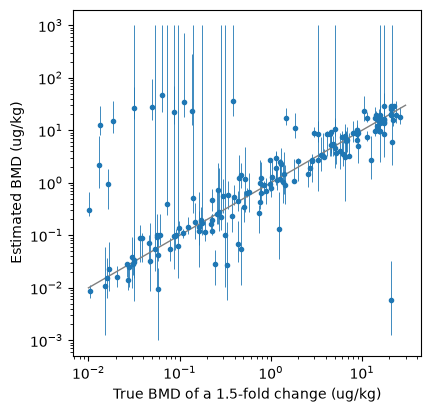

169 genes; the true BMD lies between the BMDL and BMDU of 69%


In [27]:
# The 1.5-fold BMDs of the genes that pass the gate, against their true BMDs within
# the doses, with bars from BMDL to BMDU.
fold = bmds.filter(bmds["passes_gate"] & (bmds["bmr"] == bmr[1].label))
true_bmd = truth.benchmark_doses(
    "Hepatocyte", fold["feature_id"].tolist(), log2_change=np.log2(1.5)
)
estimate, lower, upper = (np.asarray(fold[name]) for name in ("bmd", "bmdl", "bmdu"))
shown = np.isfinite(estimate) & (true_bmd >= 0.01) & (true_bmd <= 30)
inside = (lower <= true_bmd) & (true_bmd <= upper)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
# A BMDL of 0 or a BMDU of infinity, a bound beyond the search, is drawn at the
# plot's edge, 1e-3 or 1e3 ug/kg.
bars = [
    estimate[shown] - np.maximum(lower[shown], 1e-3),
    np.minimum(upper[shown], 1e3) - estimate[shown],
]
ax.errorbar(true_bmd[shown], estimate[shown], yerr=bars, fmt="o", ms=3, lw=0.6)
ax.plot([0.01, 30], [0.01, 30], color="0.5", lw=1)
ax.set(
    xscale="log",
    yscale="log",
    xlabel=f"True BMD of a 1.5-fold change ({axis.unit})",
    ylabel=f"Estimated BMD ({axis.unit})",
)
plt.show()
print(
    f"{int(shown.sum())} genes; the true BMD lies between the BMDL and BMDU of "
    f"{np.mean(inside[shown]):.0%}"
)

Each point is a gene that passes the gate: its estimated BMD of a 1.5-fold change against the true one, with a bar from the BMDL to the BMDU, and points on the grey line are exact. The BMDs scatter around the truth, and BMDL to BMDU, a two-sided 90% interval, holds the true BMD of 69% of the 169 genes: the bounds take each gene's best model as given, and with three mice per dose the best model is often not the true shape, as the curves above showed; even with the true model, the chi-square threshold covers less than 90% at three replicates; and log-CPM values compress the changes of genes with few counts. [Limits and differences](../statistics/potency.md#potency-limits) gives the coverage on simulated series.

## Choose a BMR that compares cell types

Which BMR compares the BMDs of two cell types? An SD-based BMR is a different change in each cell type, because the SD of a pseudobulk profile shrinks as its cells add up. `bmr_change` says what each BMR amounts to in log2 units:

In [28]:
for cell_type in ("Hepatocyte", "Stellate"):
    # The first row of bmr_change is the first BMR, 1.349 SD.
    change = potency.benchmark_doses(cell_type).bmr_change[0]
    print(
        f"{cell_type}: 1.349 SD is a median change of {np.nanmedian(change):.2f} log2"
    )

Hepatocyte: 1.349 SD is a median change of 0.43 log2
Stellate: 1.349 SD is a median change of 0.66 log2


With 800 cells per profile, 1.349 SD of a hepatocyte gene is a median change of 0.43 log2 units; with 40, that of a stellate gene is 0.66, half as much again. The same curve therefore has a lower SD-based BMD in hepatocytes than in stellate cells, which says more about the cells per profile than about the gene. Compare cell types on an absolute BMR, such as the 1.5-fold change above, which is the same change in every cell type, and read the BMDs of genes with enough counts in both, since log-CPM values compress the changes of genes with few counts, more so in the cell type of fewer cells ([Benchmark doses across cell types](../statistics/potency.md#benchmark-doses-across-cell-types)).

## Test a signature along dose

Does a signature, a set of genes scored in each sample, respond to the dose in the direction expected? Trials of drugs follow such scores, such as an interferon signature that a drug is meant to lower. {api}`gsva` scores a set in each sample of a cell type, and {api}`dose_response` tests the scores as it tests genes. Here two sets of the hepatocytes, from the truth: 30 genes that fall along Hill curves, and 30 flat genes as a control:

In [29]:
# Two sets of the hepatocytes' genes: 30 that fall along Hill curves, and 30 flat.
genes = truth.table("Hepatocyte")
ids = np.array(genes["feature_id"].tolist())
change = np.asarray(genes["max_log2_change"])
falling = (np.array(genes["shape"].tolist()) == "hill") & (change < 0)
sets = {"falling": ids[falling][:30].tolist(), "flat": ids[change == 0][:30].tolist()}

# One GSVA score per hepatocyte sample and set.
scores = gsva(cube, sets, group="Hepatocyte")

# How many of each set's genes GSVA scored, and in how many samples.
n_samples = len(scores.profiles)
for name, n in zip(scores.gene_sets, scores.n_genes):
    print(f"{name}: {n} of {len(sets[name])} genes scored in {n_samples} samples")

falling: 25 of 30 genes scored in 27 samples
flat: 27 of 30 genes scored in 27 samples


GSVA scores only the genes that pass its expression filter in the cell type, so each set keeps fewer than its 30 genes. It ranks each sample's genes and scores a set high where its genes rank high, so the score of the falling set should fall with dose. The direction is known before the data, so the tests are one-sided: the linear trend and the MCP step, each for a fall:

In [30]:
# The linear trend and the MCP step of each set, one-sided for a fall.
signatures = dose_response(
    scores,
    Design(cube.samples, "~ 1"),
    dose=axis,
    tests=("linear_trend", "mcp"),
    direction="down",
    rng=1,
)

# Each set's slope, the shape of its most extreme t, that t and its p-value.
trend, mcp = signatures.table(name="linear_trend"), signatures.table(name="mcp")
for i, name in enumerate(trend["gene_set"]):
    print(
        f"{name:<8} slope {trend['estimate'][i]:+.2f}  shape {mcp['contrast'][i]:<12} "
        f"t {mcp['t'][i]:6.1f}  one-sided p {mcp['p_value'][i]:.2g}"
    )

falling  slope -0.28  shape emax_2       t  -11.8  one-sided p 1.4e-09
flat     slope -0.06  shape exponential  t   -1.8  one-sided p 0.13


The falling set's score drops by 0.28 GSVA units per log10 unit of dose, and the MCP step finds the fall most like `emax_2`, an Emax shape that reaches half its change near 2 ug/kg, with a one-sided p-value of 1.4e-9; the flat set is not called. With two scores there is no moderation, and each is tested on its own linear model, the model that DoseFinding's `MCTtest` fits, which reports the t-statistics of decreasing shapes as positive where CytePool gives them negative. The figure draws each set's change in score from the vehicle; for a result of scores, `genes` names the gene sets:

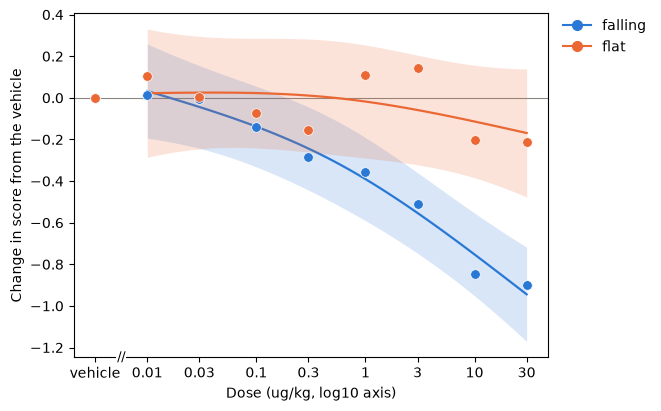

In [31]:
# Each set's change in score from the vehicle, with the spline and its band.
ax = plot_dose_response(signatures, genes=["falling", "flat"])
plt.show()

The points are each dose's change in score from the vehicle, and the lines the spline with its 95% band, which stays two-sided. The falling set falls steadily from 0.1 ug/kg; the flat set wanders within about 0.2 of 0, which GSVA's ranking of each sample's genes against one another allows, so a flat set scored beside a signature shows how far a score moves without its genes changing.

## Read next

[Which genes respond to dose](../statistics/dose_response.md#dose-response-tests) explains the four tests and how they share one fit, [Curves with a band](../statistics/dose_response.md#dose-response-curves) the curves, [Curves of named models](../statistics/dose_response.md#dose-response-model-curves) the models, their variance modes and how to read their table, and [Checking a dose design](../statistics/dose_response.md#dose-design-check) the statuses of the check. [Simulated dose series with known curves](../statistics/dose_response.md#simulated-dose-series) draws series like this one at other designs, to see what a design finds before it is run. [Trends, doses against the vehicle and candidate shapes](../statistics/dose_response.md#dose-response-contrasts) explains the multiple contrast tests, [Which genes count as responding](../statistics/dose_response.md#dose-response-gate) the gate and its fold change, [Could the calls come from noise?](../statistics/dose_response.md#dose-permutation-check) the permutation check, [From which dose a gene responds](../statistics/dose_response.md#lowest-effective-dose) the lowest effective doses, and [Potency and points of departure](../statistics/potency.md) benchmark doses, their bounds and the checks of regulatory guidance. [Signatures along dose](../statistics/dose_response.md#dose-response-signatures) explains the tests of scores, and [Tests in one direction](../statistics/dose_response.md#one-sided-dose-tests) the one-sided tests.